In [4]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install scipy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy import interpolate
from scipy import differentiate

In [115]:
data_PP0 = np.array([0.99, 0.98, 0.97, 0.95, 0.90, 0.85, 0.80, 0.77, 0.75, 0.73, 0.71])
data_V = np.array([161.7, 161.5, 161.0, 160.2, 158.8, 157.2, 155.2, 152.9, 148.9, 145.1, 140.9])
r_k = -4.15/np.log10(data_PP0)
t = 3.54*(-5/(np.log(data_PP0)))**(1/3)
r_p = r_k + t
r_k_mean = []
r_p_mean = []
delta_t = []
delta_V = []
for i in range(len(data_PP0)-1):
    delta_t.append(t[i]-t[i+1])
    delta_V.append(data_V[i]-data_V[i+1])
    r_k_mean.append(np.mean([r_k[i], r_k[i+1]]))
    r_p_mean.append(np.mean([r_p[i], r_p[i+1]]))
delta_t = np.array(delta_t)
delta_V = np.array(delta_V)
r_k_mean = np.array(r_k_mean)
r_p_mean = np.array(r_p_mean)
delta_V_f = 0.0015468*delta_V
s_t = []
V_p = []
S_p = []
sS_p = []
sV_p = []
sum_S = 0.0
sum_V = 0.0
for i in range(len(data_PP0)-1):
    s_t.append(sum_S*delta_t[i]/10000)
    V_p.append((delta_V_f[i]-s_t[i])*(r_p_mean[i]/r_k_mean[i])**2)
    S_p.append(2*V_p[i]/r_p_mean[i]*10**4)
    sum_S += S_p[i]
    sS_p.append(sum_S)
    sum_V += V_p[i]
    sV_p.append(sum_V)

In [116]:
d = 2*r_p_mean
sS_p = np.array(sS_p)
idx_sort = np.argsort(d)
sort_d_mean = d[idx_sort]
sort_sS_p = sS_p[idx_sort]
f = interpolate.PchipInterpolator(sort_d_mean, sort_sS_p)
x = np.linspace(40, 1500, 100)
df = f.derivative()
y_df = -df(x)
y_df = np.clip(y_df, 0, None)
y_df_log = y_df * x * np.log(10)

y_df_pr = [0]
for i in range(len(S_p)-1):
    y_df_pr.append(S_p[i+1]/(d[i]-d[i+1]))
y_df_pr_log = [0]
for i in range(len(S_p)-1):
    y_df_pr_log.append(S_p[i+1]/(2*(np.log10(r_p_mean[i])-np.log10(r_p_mean[i+1]))))

In [118]:
d = 2*r_p_mean
sV_p = np.array(sV_p)
idx_sort = np.argsort(d)
sort_d_mean = d[idx_sort]
sort_sV_p = sV_p[idx_sort]
f_V = interpolate.PchipInterpolator(sort_d_mean, sort_sV_p)
x_V = np.linspace(40, 1500, 100)
df_V = f_V.derivative()
y_df_V = -df_V(x)
y_df_V = np.clip(y_df_V, 0, None)
y_df_log_V = y_df_V * x_V * np.log(10)

y_df_pr_V = [0]
for i in range(len(V_p)-1):
    y_df_pr_V.append(V_p[i+1]/(d[i]-d[i+1]))
y_df_pr_log_V = [0]
for i in range(len(V_p)-1):
    y_df_pr_log_V.append(V_p[i+1]/(2*(np.log10(r_p_mean[i])-np.log10(r_p_mean[i+1]))))

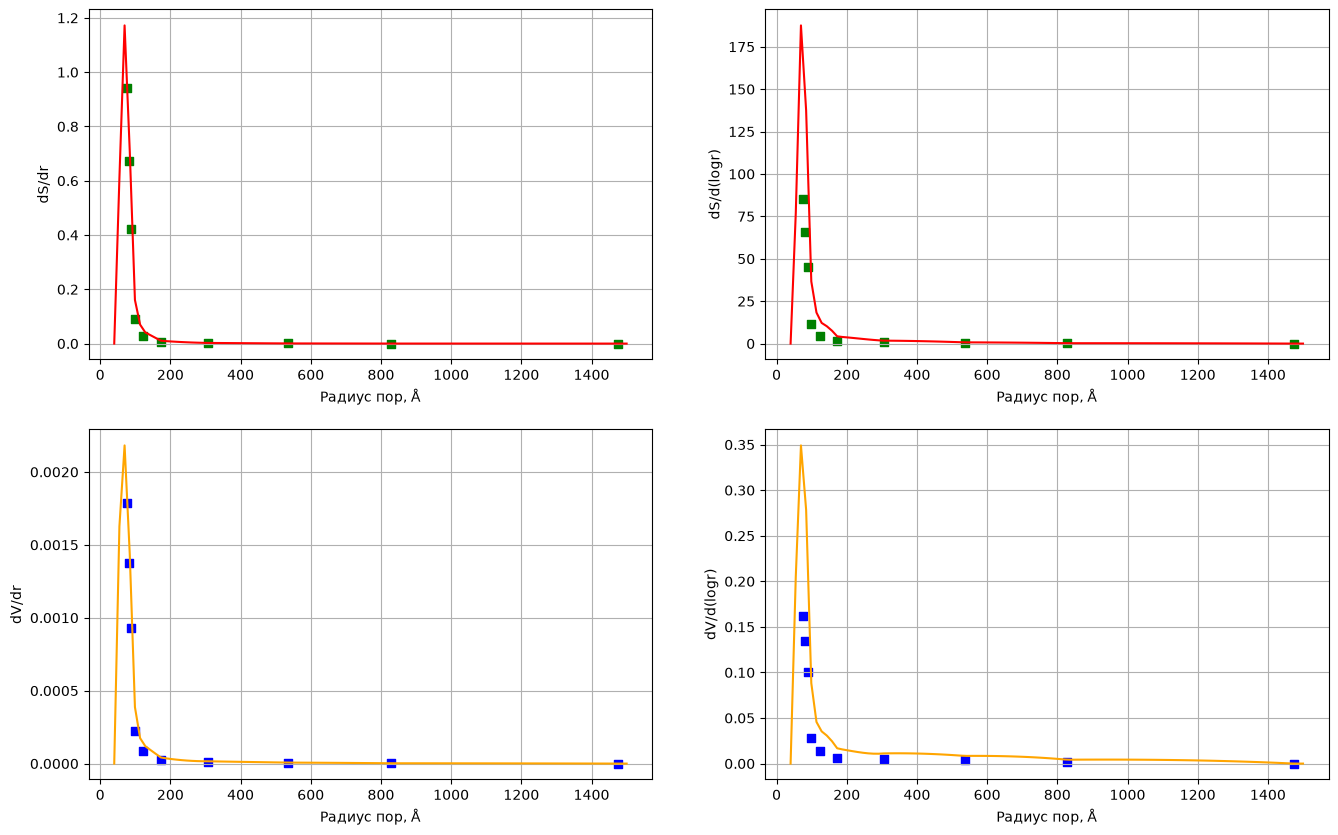

<Figure size 640x480 with 0 Axes>

In [122]:
fig, ax = plt.subplots(2, 2, figsize = (16, 10))

ax[0, 0].scatter(d, y_df_pr, c ='g', marker = 's')
ax[0, 0].plot(x, y_df, c = 'r')
ax[0, 0].grid(True)
ax[0, 0].set_xlabel('Радиус пор, Å')
ax[0, 0].set_ylabel('dS/dr')

ax[0, 1].scatter(d, y_df_pr_log, c ='g', marker = 's')
ax[0, 1].plot(x, y_df_log, c = 'r')
ax[0, 1].grid(True)
ax[0, 1].set_xlabel('Радиус пор, Å')
ax[0, 1].set_ylabel('dS/d(logr)')

ax[1, 0].scatter(d, y_df_pr_V, c ='b', marker = 's')
ax[1, 0].plot(x_V, y_df_V, c = 'orange')
ax[1, 0].grid(True)
ax[1, 0].set_xlabel('Радиус пор, Å')
ax[1, 0].set_ylabel('dV/dr')

ax[1, 1].scatter(d, y_df_pr_log_V, c ='b', marker = 's')
ax[1, 1].plot(x_V, y_df_log_V, c = 'orange')
ax[1, 1].grid(True)
ax[1, 1].set_xlabel('Радиус пор, Å')
ax[1, 1].set_ylabel('dV/d(logr)')

plt.show()
plt.tight_layout()